<a href="https://colab.research.google.com/github/walevez/ProcesamientoDelHabla/blob/main/CHAVEZ_WALTER_PH_TP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 PROCESAMIENTO DEL HABLA: webscrapping

**Crea una copia de este notebook en tu google colab**

**Renombra el notebook con el siguiente formato APELLIDO_NOMBRE_PH_TP1.ipynb**

**CHAVEZ WALTER EMANUEL**


* Resolver las consignas comentando el código fuente, indicando desde dónde fue extraido o generado.

* Explicar y justificar cada paso realizado usando los bloques de texto.

* Publique enlace público a su notebook en google colab y también enlace a su repositorio github de la materia.


## EJERCICIO CONSIGNA

* Cree una nube de palabras de un texto en español.

* Dicho texto puede ser descargado de Internet (webscrapping) o extraído del dataset de alguna librería.

* Puede usar cualquier libreria o herramienta para obtener el texto de su interés.

* En este notebook explica el paso a paso del proceso.



## 1- Webscrapping

Extrae un texto de Internet de una sóla página web usando alguna de las técnicas de webscrapping vistas en clase. Busca el discurso de alguna persona quien te inspire o haya dado una charla motivadora.

No puedes repetir ni usar ni el mismo texto ni la misma web que otra persona quien ya entregó en el foro.

Abajo añade los bloques de código y texto necesarios. Explica paso a paso como descargaste el texto de tu interés.


In [ ]:
# instalacion de las bibliotecas
! pip install requests beautifulsoup4
! python -m spacy download es_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 37.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# importacion de las bibliotecas previamente instaladas
import requests
from bs4 import BeautifulSoup
import spacy
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import re
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

## Solicitud de los datos

### Sitio bloqueado

Para poder hacer la solicitud al sitio donde realice el scraping tuve que poner una variable con contenga la cabecera que simula que el pedido es de un navegador web, porque si no lo hacia, a la segunda solicitud el sitio me bloqueaba la ip del notebook.


In [ ]:
# varible que acompania el pedido de los datos
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'
}

# url de la que se solicita los datos
url = 'https://www.sinpermiso.info/textos/la-promesa-de-las-energias-renovables-entrevista-con-bill-mckibben/'

# bloque de manejo de errores con try y except
try:
  # llamo a la funcion request.get y le paso como parametros url y headers, aca se almacenan el contenido y el estado de la peticion
  response = requests.get(url, headers=headers)

  # este metodo verifica si la recepcion fue exitosa, si hay algun error lo captura el metodo except
  response.raise_for_status()

  # utilizo la funcion BeautifulSoup y le paso como paremetros response.content(el contenido obtenido de la pagina) y html.parser para procesar el contenido html y crear el objeto soup
  soup = BeautifulSoup(response.content, 'html.parser')

  # si todo salio bien imprimi el mensaje
  print("Conexión exitosa")

# si hubo algun error se guarda como e, y se imprime con detalles.
except Exception as e:
  print(f"Error: {e}")

Conexión exitosa


### Tratamiento de los datos extraidos

In [ ]:
# con la siguiente linea extraigo solo el tema de la entrevista
entrevista_words = soup.find("section", class_ = "field-body")

# hora solo seleccion el contenido de los parrafos que estan dentro de field-body
entrevista_p = entrevista_words.find_all('p')

# creo la lista donde voy a almacenar todos los elementos
oraciones = []

# realizo una interacion sobre cada elemento de la variable entrevista_p
for p in entrevista_p:
  #voy agregando cada elemento en la lista oraciones con el parametro strip que borra si hay espacios al final de cada string
  oraciones.append(p.get_text(strip=True))

# ahora extraigo cada elemento de la lista oraciones y las concateno en forma de texto en la variable texto_completo
texto_completo = " ".join(oraciones)

# imprimo el contenido de la variable texto_completo
print(texto_completo)

En septiembre de 1989, junto con un poema de John Updike y un relato de Muriel Spark, la revistaThe New Yorkerpublicó un artículo titulado «The End of Nature», acerca del aumento de los gases de efecto invernadero y el calentamiento global. Lo había escrito un autor en la veintena llamado Bill McKibben, que lleva desde entonces contando esa historia y convocándonos a la acción. McKibben, destacado activista medioambiental en materia de cambio climático y naturaleza, contribuyó a fundar la campaña climática global350.org, así como Third Act, que organiza a personas mayores de 60 años para que actúen en cuestiones climáticas y de justicia. Es autor asimismo de 20 libros, empezando porThe End of Nature[El fin de la naturaleza, ed. Carbrame, 2025] y, más recientemente,Here Comes the Sun:A Last Chance for the Climate and a Fresh Chance for Civilization] [“Ya llega el sol: Una última oportunidad para el clima y una nueva oportunidad para la civilización”], libro acerca del cual le entrevista

## 2- Preprocesamiento

### 2.1 Muestra las stop words que tenga tu texto.

In [ ]:
# cargo el modulo principal en espaniol de la biblioteca spacy en la variable nlp
nlp = spacy.load('es_core_news_sm')

# en la variable doc llamo a la varible y nlp y le paso como parametro la variable texto_completo
doc = nlp(texto_completo)

# realizo una list comprehension que la llamo stopword_en_doc
# esta interando los elementos de doc con el nombre de token extrayendo el texto del mismo, si ese texto es un stop word lo incluye a la lista
stopwords_en_doc=[token.text for token in doc if token.is_stop]

# imprimo las stop words usando usando set que  elimina duplicados del conjunto
print(set(stopwords_en_doc))

{'cuenta', 'todas', 'La', 'existen', 'se', 'pero', 'otro', 'nosotros', 'sido', 'o', 'mucho', 'tú', 'haciendo', 'para', 'cierta', 'dijo', 'Ya', 'largo', 'mismo', 'fue', 'casi', 'Había', 'esta', 'uno', 'gran', 'encuentra', 'También', 'cómo', 'hasta', 'nueva', 'tiene', 'mejor', 'alrededor', 'Quizás', 'les', 'estaban', 'Cuando', 'los', 'nos', 'en', 'estado', 'Estados', 'primero', 'sobre', 'sabemos', 'tanto', 'aproximadamente', 'cuatro', 'su', 'Hay', 'había', 'Creo', 'hace', 'poder', 'donde', 'Nueva', 'estas', 'Y', 'lado', 'con', 'durante', 'bien', 'fuera', 'no', 'nuestros', 'trata', 'le', 'vez', 'De', 'A', 'verdad', 'e', 'primera', 'ha', 'tenía', 'medio', 'a', 'hay', 'Al', 'el', 'Nos', 'dice', 'ello', 'ya', 'qué', 'usted', 'Sí', 'todo', 'incluso', 'nuevo', 'de', 'Hemos', 'En', 'muy', 'será', 'unos', 'Tan', 'repente', 'Todas', 'supuesto', 'Hace', 'desde', 'Quiere', 'Mientras', 'hacemos', 'por', 'saber', 'nuestras', 'sin', 'Por', 'tan', 'unas', 'Entre', 'Cómo', 'ver', 'haya', 'era', 'dos', '

### 2.2 Quita las stop-words, caracteres extraños del texto. Utiliza el texto restante para crear una nube de palabras. Usa la biblioteca worldcloud de python.

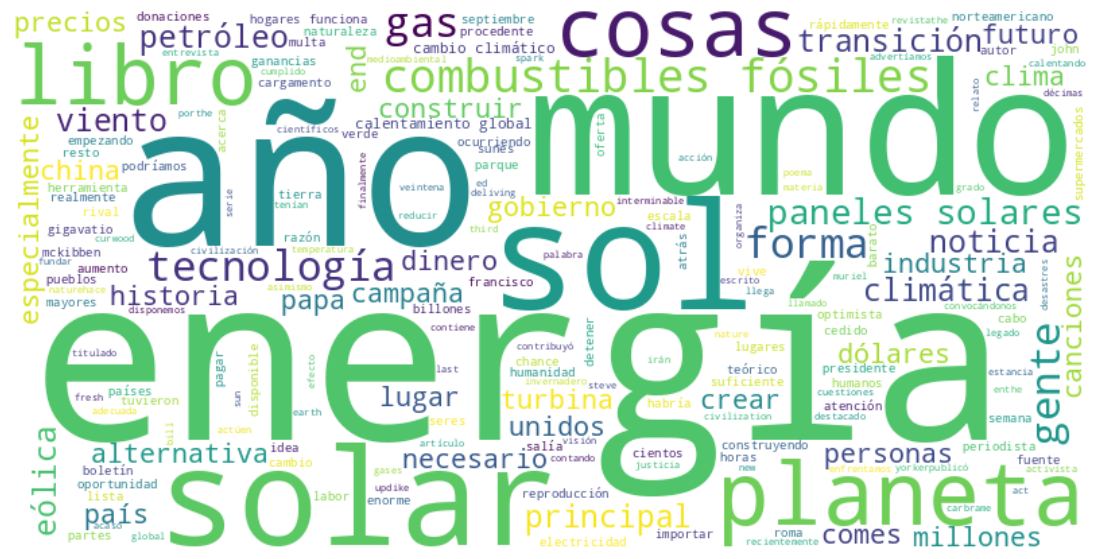

In [ ]:
# como en el list comprehension anterior guardo en la variable palabras los tokens de doc, que son distintos de stop word y caracteres que
palabras = [t.text.lower() for t in doc if not t.is_stop and t.is_alpha]
# agrego los tokens en la variable texto
texto_limpio = " ".join(palabras)

# en la variable wc guardamos la funcion WordCloud, le paso como parametro el ancho y el alto
# el color de fondo y llamamos al metodo generate, donde le pasamos el texto con las palabras
wc = WordCloud(width=800, height=400, background_color="white").generate(texto_limpio)

plt.figure(figsize=(15,7))
# muestra la interpolacion bilinear
plt.imshow(wc, interpolation="bilinear")
# oculta los ejes
plt.axis("off")
# muestra el grafico
plt.show()

### 2.3 Usando el texto que conseguiste en el punto 1).



#### 2.3.1 Limpia y preprocesa el texto, descomponelo en oraciones, arma una matriz documento-vocabulario.


In [ ]:
# promt: necesito que en cada punto del string de la variable "texto completo", sea el final de un elemento de una lista y el inicio de otro.
# We will use spacy's sentence segmenter to split the 'texto_completo' into individual sentences.
corpus = nlp(texto_completo)

# itera y guarda cada sentencia que contiene corpus previamente quitando los espacios.
# aproveche de incluir re para quitar cualquier caracter que no sea letra ni numero, y lower para hacer el texto minusculas.
documentos = [re.sub(r'[^\w\s]','', sent.text.strip().lower()) for sent in corpus.sents if sent.text.strip()]

# llamamos a la clase CountVectorizer y la guardamos en la variable
vectorizador = CountVectorizer()

# usamos la variable vectorizador y le pasamos el metodo fit_transformo con la variable documentos como parametro.
# esto crea un matriz que contiene n filas como la cantidad de documentos y m columnas como palabras no repetidas que contiene el corpus.
# va asignando los valores a las celdas segun la cantidad de veces que se repite el tokens.
matriz_doc_voc = vectorizador.fit_transform(documentos)

# muestras el contenido en forma de matriz
print(matriz_doc_voc.toarray())

[[0 0 1 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 1 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 1]]



#### 2.3.2 Determina la longitud de tu vocabulario.

In [ ]:
# promt: necesito determinar la longitud de la matriz: matriz_doc_voc, que metodo debo usar?
vocabulario_longitud = len(vectorizador.vocabulary_)

print(f"La longitud del vocabulario es: {vocabulario_longitud}")

La longitud del vocabulario es: 834



#### 2.3.3. Aplica TF-IDF a tu matriz documento-vocabulario

In [ ]:
# inicializa el vectorizador
tfidf_vectorizer = TfidfVectorizer()

# el modelo aprender el vacabulario ingresado de documentos
tfidf_vectorizer.fit(documentos)

# calcula y aplica los pesos a los texto generando la matriz final
tfidf_matrix = tfidf_vectorizer.transform(documentos)

# muestra en modelo en forma de array
print(tfidf_matrix.toarray())

[[0.         0.         0.18420758 ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.34010091 0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.47591501]]


In [ ]:
# forma de la matriz, 86 filas x 834 columnas
print(tfidf_matrix.shape)

(86, 834)


Explica el formato de tu matriz resultante: documentos, vocabulario, tamaño. Brinda tus conclusiones.

# Conclusiones

Agregue aquí sus conclusiones sobre este trabajo práctico. Puede ser también parte del texto que posteará en el foro.

Al resolver cada punto del trabajo practico comprendi mejor el pipeline de procesamiento de texto.

La nube de palabras, hecha con tokens sin stopwords, muestra por frecuencia de que trata el corpus (energias renovables, segun la entrevista a McKibben).

La matriz documento-vocabulario tiene 86 oraciones (filas) y 834 terminos (columnas); cada celda es la frecuencia del termino en esa oracion.

TF-IDF pondera esas frecuencias respecto de todo el corpus: baja el peso de palabras comunes y sube el de las más distintivas.